# 01 - Data cleaning & validation
Loads the raw Nassau Candy orders, validates them and rebuilds a **corrected lead time**.

**Finding:** raw `Ship Date - Order Date` is 900-1,640 days because each Order-ID-year cohort carries a constant offset. The offset is estimated from the cohort's Same Day orders (nominally 0 days) and removed.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]          # notebooks/<stage>/ -> project root
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from src import config as C
from src import data_prep

In [2]:
raw = data_prep.load_raw()
print(raw.shape)
raw.head()

(10194, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [3]:
validated, report = data_prep.clean_and_validate(raw)
report

{'rows_raw': 10194,
 'duplicate_rows_removed': 0,
 'unparseable_dates_removed': 0,
 'missing_values_total': 0,
 'financial_identity_mismatches': 0,
 'non_positive_sales_units_removed': 0,
 'ship_before_order_removed': 0,
 'unmapped_products_removed': 0,
 'raw_lead_time_range_days': [904, 1642],
 'cohort_offsets_days': {2021: 904.0,
  2022: 1269.0,
  2023: 1269.0,
  2024: 1635.0},
 'corrected_lead_time_range_days': [0.0, 11.0],
 'rows_validated': 10194}

In [4]:
validated.groupby('Order Cohort')[['Raw Lead Time','Cohort Offset','Lead Time']].agg(['min','median','max']).round(1)

Raw Lead Time               Cohort Offset                 Lead Time             
                       min  median   max           min  median     max       min median   max
Order Cohort                                                                                 
2021                   904   908.0   915         904.0   904.0   904.0       0.0    4.0  11.0
2022                  1269  1273.0  1277        1269.0  1269.0  1269.0       0.0    4.0   8.0
2023                  1269  1273.0  1276        1269.0  1269.0  1269.0       0.0    4.0   7.0
2024                  1634  1639.0  1642        1635.0  1635.0  1635.0       0.0    4.0   7.0

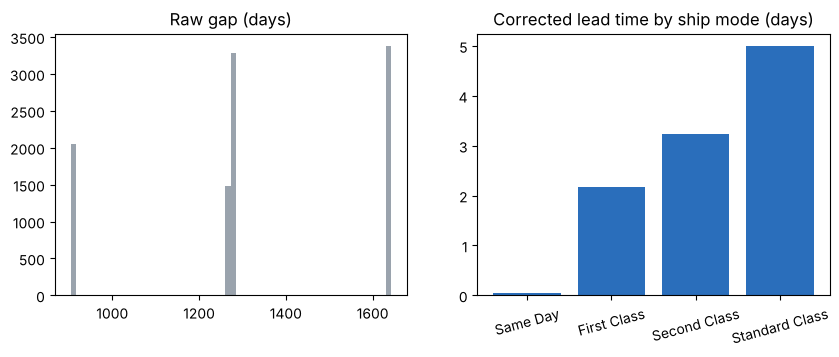

Ship Mode
Same Day          0.05
First Class       2.18
Second Class      3.24
Standard Class    5.00
Name: Lead Time, dtype: float64

In [5]:
order = ['Same Day','First Class','Second Class','Standard Class']
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(validated['Raw Lead Time'], bins=60, color='#9aa3ad'); ax[0].set(title='Raw gap (days)')
m = validated.groupby('Ship Mode')['Lead Time'].mean().reindex(order)
ax[1].bar(order, m.values, color='#2a6ebb'); ax[1].set(title='Corrected lead time by ship mode (days)')
ax[1].tick_params(axis='x', rotation=15); plt.show()
m.round(2)

In [6]:
C.PROCESSED.mkdir(parents=True, exist_ok=True)
validated.to_csv(C.PROCESSED / 'orders_validated.csv', index=False)
validated[['Product Name','Origin Factory','State/Province','Distance Miles','Lead Time','Ship Mode']].head()

,Product Name,Origin Factory,State/Province,Distance Miles,Lead Time,Ship Mode
0,Wonka Bar - Milk Chocolate,Wicked Choccy's,Texas,1070.967399,5.0,Standard Class
1,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Illinois,712.105887,5.0,Standard Class
2,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Illinois,1343.403049,5.0,Standard Class
3,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Illinois,1343.403049,5.0,Standard Class
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Pennsylvania,635.653917,8.0,Standard Class
